# Notebook 8 — SOLUTION

## Short version

**There is no difference.** All 150 rates were drawn from one lognormal
distribution, median 4 spikes/s, and region was assigned without reference to
rate. The true difference is exactly zero.

Two facts about firing rates do the damage, and they need each other:

1. **The distribution is strongly right-skewed.** Rates span from 0.2 to 110
   spikes/s here. The mean of such a distribution is carried by its tail, so a
   sample of 10 units usually **misses the tail and comes out too low**.
2. **The sample mean and the sample SD move together.** The same missing large
   values that pull the mean down also pull the SD down. So a group that missed
   the tail looks not just quieter but *more precisely measured*.

Welch's t-test uses each group's own SD, so it reads that shrunken SD as
precision and reports a confident difference. Region A here has SD 2.70 against
region B's 17.07, entirely because 10 draws did not reach the tail that 140 draws
did.

Measured on this generative model, **Welch's t-test rejects at p < 0.05 about 17%
of the time with the null exactly true**, and the small group appears lower in
essentially every one of those cases. That is a systematically-signed false
positive, not a coin flip.

Three things that are easy to guess wrong:

- **Student's pooled t-test is much *safer* here than Welch's** (5.5% vs 17%),
  which is the reverse of the usual advice. Pooling the variance lets the large
  group's honest SD dominate, so the standard error cannot collapse.
- **Equal group sizes fix it.** At 30 vs 30 the skew barely matters and Welch is
  slightly conservative. It is skew **plus** imbalance that breaks the test.
- **The median says the opposite.** Region A's median rate is 4.69 against region
  B's 4.11, i.e. 14% *higher*, while the means differ by 47% the other way. When
  the mean and the median disagree that violently, the mean is not the summary you
  want.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams['font.family']       = 'Arial'
plt.rcParams['font.sans-serif']   = ['Arial', 'DejaVu Sans']
plt.rcParams['axes.spines.top']   = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['pdf.fonttype']      = 42
plt.rcParams['ps.fonttype']       = 42

C_A, C_B = 'tab:orange', 'tab:blue'


In [2]:
d = np.load('data/data.npz')
spike_counts = d['spike_counts']            # (units,) spikes in the session
duration     = float(d['duration'])         # s
region       = d['region']                  # (units,) 0 = region A, 1 = region B

rate = spike_counts / duration              # spikes/s, one number per unit
A, B = rate[region == 0], rate[region == 1]
print(f'{rate.size} units: {A.size} in region A, {B.size} in region B')
print(f'{duration/60:.0f} min recording')
print(f'region A: mean {A.mean():.2f} spikes/s')
print(f'region B: mean {B.mean():.2f} spikes/s')


150 units: 10 in region A, 140 in region B
30 min recording
region A: mean 5.10 spikes/s
region B: mean 9.57 spikes/s


## Evidence 1 — Look at the distribution

The rate distribution is lognormal: near-symmetric on a log axis, wildly skewed
on a linear one. On the linear axis most units are crowded near zero and a few
sit far out to the right, and it is those few that set the mean.

Note where the two group means fall relative to the two medians.


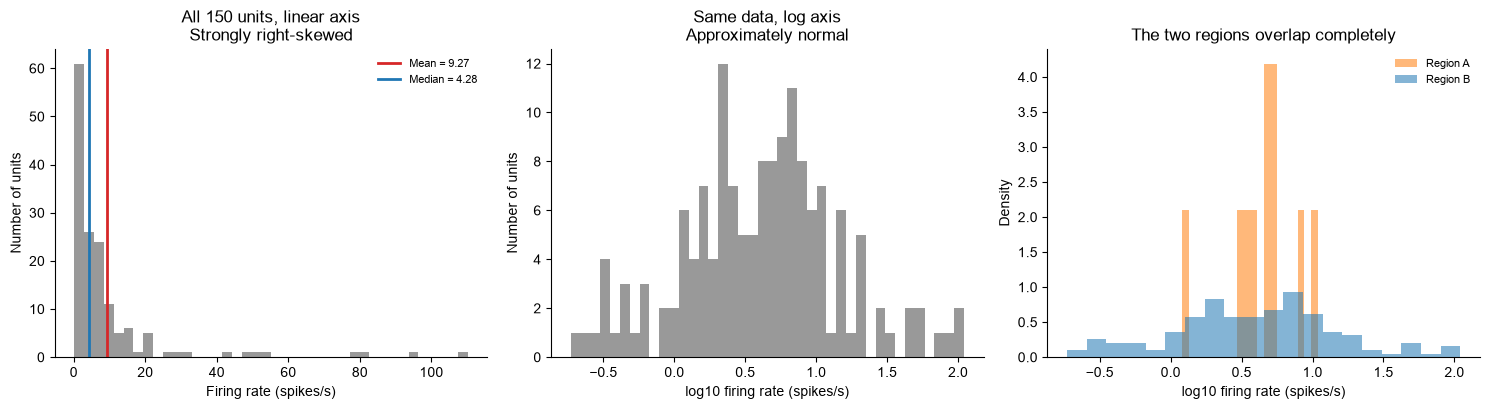

              n     mean   median       SD      max
region A     10     5.10     4.69     2.70     10.9
region B    140     9.57     4.11    17.07    110.1

ratio of MEANS   A/B : 0.533  (-47%)
ratio of MEDIANS A/B : 1.141  (+14%)   <- opposite sign


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

axes[0].hist(rate, bins=40, color='0.6')
axes[0].axvline(np.mean(rate), color='tab:red', lw=2,
                label=f'Mean = {np.mean(rate):.2f}')
axes[0].axvline(np.median(rate), color='tab:blue', lw=2,
                label=f'Median = {np.median(rate):.2f}')
axes[0].set_xlabel('Firing rate (spikes/s)')
axes[0].set_ylabel('Number of units')
axes[0].set_title('All 150 units, linear axis\nStrongly right-skewed')
axes[0].legend(frameon=False, fontsize=8)

axes[1].hist(np.log10(rate), bins=40, color='0.6')
axes[1].set_xlabel('log10 firing rate (spikes/s)')
axes[1].set_ylabel('Number of units')
axes[1].set_title('Same data, log axis\nApproximately normal')

for g, c, lab in ((A, C_A, 'Region A'), (B, C_B, 'Region B')):
    axes[2].hist(np.log10(g), bins=20, color=c, alpha=0.55, density=True, label=lab)
axes[2].set_xlabel('log10 firing rate (spikes/s)')
axes[2].set_ylabel('Density')
axes[2].set_title('The two regions overlap completely')
axes[2].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

print(f'{"":10s} {"n":>4s} {"mean":>8s} {"median":>8s} {"SD":>8s} {"max":>8s}')
for lab, g in (('region A', A), ('region B', B)):
    print(f'{lab:10s} {g.size:4d} {g.mean():8.2f} {np.median(g):8.2f} '
          f'{g.std(ddof=1):8.2f} {g.max():8.1f}')
print(f'\nratio of MEANS   A/B : {A.mean()/B.mean():.3f}  '
      f'({(A.mean()/B.mean()-1)*100:+.0f}%)')
print(f'ratio of MEDIANS A/B : {np.median(A)/np.median(B):.3f}  '
      f'({(np.median(A)/np.median(B)-1)*100:+.0f}%)   <- opposite sign')


## Evidence 2 — Which tests are actually calibrated

The direct check: generate many experiments from the same distribution for both
groups, so the null is exactly true, and count how often each test rejects.

Also shown, and it is the key to the whole thing, is the same comparison with
**equal** group sizes. Skew alone does not break the t-test. Skew with imbalance
does.


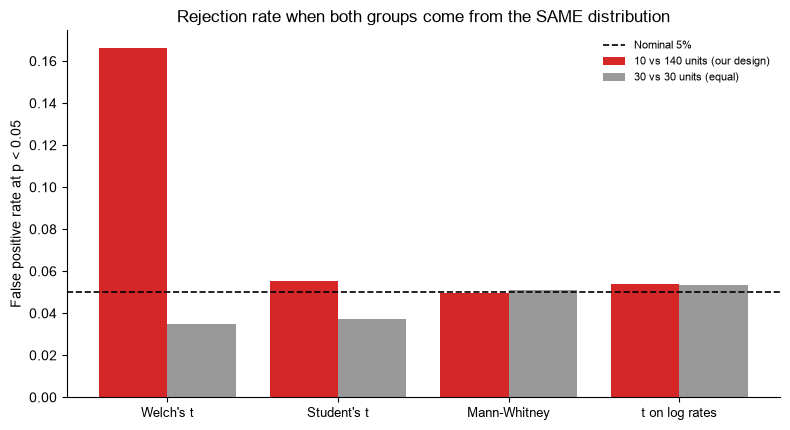

test                10 vs 140   30 vs 30
Welch's t               0.166      0.035
Student's t             0.055      0.037
Mann-Whitney            0.050      0.051
t on log rates          0.054      0.053

When Welch rejects, the small group is the lower one 99% of the time.

On our actual dataset:
  Welch's t             : p = 0.0091
  Student's t           : p = 0.4107
  Mann-Whitney          : p = 0.8124
  t on log rates        : p = 0.6544
  permutation on means  : p = 0.4170


In [4]:
MED, SIG = 4.0, 1.2         # the generative parameters (see generate_data.py)

def false_positive_rates(n1, n2, nrep=8000, seed=0):
    """Both groups from the SAME lognormal: everything below should be 0.05."""
    rng = np.random.default_rng(seed)
    a = MED * np.exp(rng.normal(0, SIG, (nrep, n1)))
    b = MED * np.exp(rng.normal(0, SIG, (nrep, n2)))
    out = {
      "Welch's t":        stats.ttest_ind(a, b, axis=1, equal_var=False).pvalue,
      "Student's t":      stats.ttest_ind(a, b, axis=1, equal_var=True).pvalue,
      'Mann-Whitney':     stats.mannwhitneyu(a, b, axis=1,
                                             alternative='two-sided').pvalue,
      't on log rates':   stats.ttest_ind(np.log(a), np.log(b), axis=1,
                                          equal_var=False).pvalue,
    }
    small_lower = (a.mean(1) < b.mean(1))
    return {k: np.mean(v < 0.05) for k, v in out.items()}, \
           np.mean(small_lower[out["Welch's t"] < 0.05])

unequal, dir_unequal = false_positive_rates(A.size, B.size)
equal, _             = false_positive_rates(30, 30)

# A permutation test on the observed data (no distributional assumption at all)
rng = np.random.default_rng(1)
pooled = np.concatenate([A, B]); obs = abs(A.mean() - B.mean())
idx = np.argsort(rng.random((20000, pooled.size)), axis=1)
pm = pooled[idx]
dperm = np.abs(pm[:, :A.size].mean(1) - pm[:, A.size:].mean(1))
p_perm = (np.sum(dperm >= obs) + 1) / (dperm.size + 1)

names = list(unequal)
x = np.arange(len(names))
fig, ax = plt.subplots(figsize=(8.0, 4.4))
ax.bar(x - 0.2, [unequal[k] for k in names], 0.4, color='tab:red',
       label=f'{A.size} vs {B.size} units (our design)')
ax.bar(x + 0.2, [equal[k] for k in names], 0.4, color='0.6',
       label='30 vs 30 units (equal)')
ax.axhline(0.05, color='k', ls='--', lw=1.2, label='Nominal 5%')
ax.set_xticks(x); ax.set_xticklabels(names, fontsize=9)
ax.set_ylabel('False positive rate at p < 0.05')
ax.set_title('Rejection rate when both groups come from the SAME distribution')
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

print(f'{"test":18s} {f"{A.size} vs {B.size}":>10s} {"30 vs 30":>10s}')
for k in names:
    print(f'{k:18s} {unequal[k]:10.3f} {equal[k]:10.3f}')
print(f'\nWhen Welch rejects, the small group is the lower one '
      f'{dir_unequal*100:.0f}% of the time.')
print(f'\nOn our actual dataset:')
print(f"  Welch's t             : p = {stats.ttest_ind(A, B, equal_var=False).pvalue:.4f}")
print(f"  Student's t           : p = {stats.ttest_ind(A, B, equal_var=True).pvalue:.4f}")
print(f'  Mann-Whitney          : p = '
      f'{stats.mannwhitneyu(A, B, alternative="two-sided").pvalue:.4f}')
print(f'  t on log rates        : p = '
      f'{stats.ttest_ind(np.log(A), np.log(B), equal_var=False).pvalue:.4f}')
print(f'  permutation on means  : p = {p_perm:.4f}')


## Evidence 3 — The mechanism: a small sample misses the tail, twice over

Draw many samples of 10 and of 140 from the true distribution and plot each
sample's mean against its own SD.

**Left:** the two clouds. The n = 10 cloud is enormously more spread out, and it
lies along a diagonal: samples with a low mean also have a low SD. The n = 140
cloud is tighter but note that even at 140 the central limit theorem has not
finished its job on a distribution this skewed.

**Right:** what Welch's standard error does about it. The red points are the
experiments where Welch rejected. They are not the extreme-mean experiments; they
are the experiments where the *small group's SD collapsed*, which is what shrinks
the denominator.


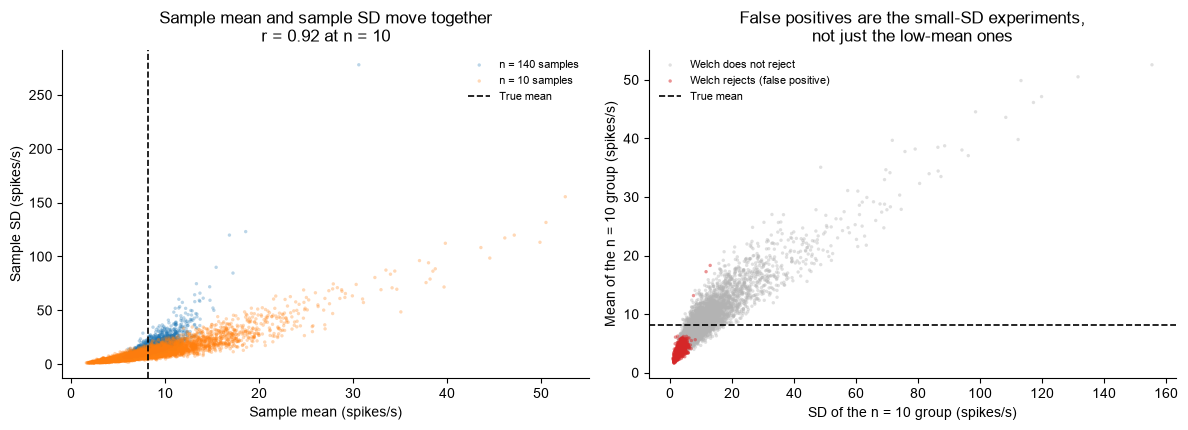

true population mean : 8.22 spikes/s   (true SD 14.75)

P(sample mean < true mean):  n = 10: 0.621   n = 140: 0.542
  (0.5 would mean the CLT has converged; it has not, even at 140)

corr(sample mean, sample SD): n = 10: 0.916   n = 140: 0.781

Among Welch false positives (n = 10 group):
  median sample mean :   3.89  vs   7.12 overall
  median sample SD   :   3.24  vs   7.56 overall
  median sample max  :  10.41  vs  23.94 overall   <- the tail is missing


In [5]:
rng = np.random.default_rng(2)
NR = 6000
sa = MED * np.exp(rng.normal(0, SIG, (NR, A.size)))
sb = MED * np.exp(rng.normal(0, SIG, (NR, B.size)))
m_a, s_a = sa.mean(1), sa.std(1, ddof=1)
m_b, s_b = sb.mean(1), sb.std(1, ddof=1)
true_mean = MED * np.exp(SIG**2 / 2)
rej = stats.ttest_ind(sa, sb, axis=1, equal_var=False).pvalue < 0.05

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))

axes[0].scatter(m_b, s_b, s=6, color=C_B, alpha=0.3, edgecolors='none',
                label=f'n = {B.size} samples')
axes[0].scatter(m_a, s_a, s=6, color=C_A, alpha=0.3, edgecolors='none',
                label=f'n = {A.size} samples')
axes[0].axvline(true_mean, color='k', ls='--', lw=1.2, label='True mean')
axes[0].set_xlabel('Sample mean (spikes/s)')
axes[0].set_ylabel('Sample SD (spikes/s)')
axes[0].set_title('Sample mean and sample SD move together\n'
                  f'r = {np.corrcoef(m_a, s_a)[0,1]:.2f} at n = {A.size}')
axes[0].legend(frameon=False, fontsize=8)

axes[1].scatter(s_a[~rej], m_a[~rej], s=6, color='0.7', alpha=0.4,
                edgecolors='none', label='Welch does not reject')
axes[1].scatter(s_a[rej], m_a[rej], s=6, color='tab:red', alpha=0.5,
                edgecolors='none', label='Welch rejects (false positive)')
axes[1].axhline(true_mean, color='k', ls='--', lw=1.2, label='True mean')
axes[1].set_xlabel(f'SD of the n = {A.size} group (spikes/s)')
axes[1].set_ylabel(f'Mean of the n = {A.size} group (spikes/s)')
axes[1].set_title('False positives are the small-SD experiments,\n'
                  'not just the low-mean ones')
axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

print(f'true population mean : {true_mean:.2f} spikes/s   '
      f'(true SD {true_mean*np.sqrt(np.exp(SIG**2)-1):.2f})')
print(f'\nP(sample mean < true mean):  n = {A.size}: '
      f'{np.mean(m_a < true_mean):.3f}   n = {B.size}: {np.mean(m_b < true_mean):.3f}')
print(f'  (0.5 would mean the CLT has converged; it has not, even at {B.size})')
print(f'\ncorr(sample mean, sample SD): n = {A.size}: {np.corrcoef(m_a, s_a)[0,1]:.3f}'
      f'   n = {B.size}: {np.corrcoef(m_b, s_b)[0,1]:.3f}')
print(f'\nAmong Welch false positives (n = {A.size} group):')
print(f'  median sample mean : {np.median(m_a[rej]):6.2f}  '
      f'vs {np.median(m_a):6.2f} overall')
print(f'  median sample SD   : {np.median(s_a[rej]):6.2f}  '
      f'vs {np.median(s_a):6.2f} overall')
print(f'  median sample max  : {np.median(sa.max(1)[rej]):6.2f}  '
      f'vs {np.median(sa.max(1)):6.2f} overall   <- the tail is missing')


## Evidence 4 — How bad it gets, as a function of imbalance and skew

Two sweeps. The false positive rate climbs as the groups get more unequal, and it
climbs with the skew of the distribution. At equal sizes Welch is fine at any
skew; at a 1-to-14 imbalance and realistic firing-rate skew it is rejecting three
times too often.

The rank test is flat and correct everywhere in both sweeps.


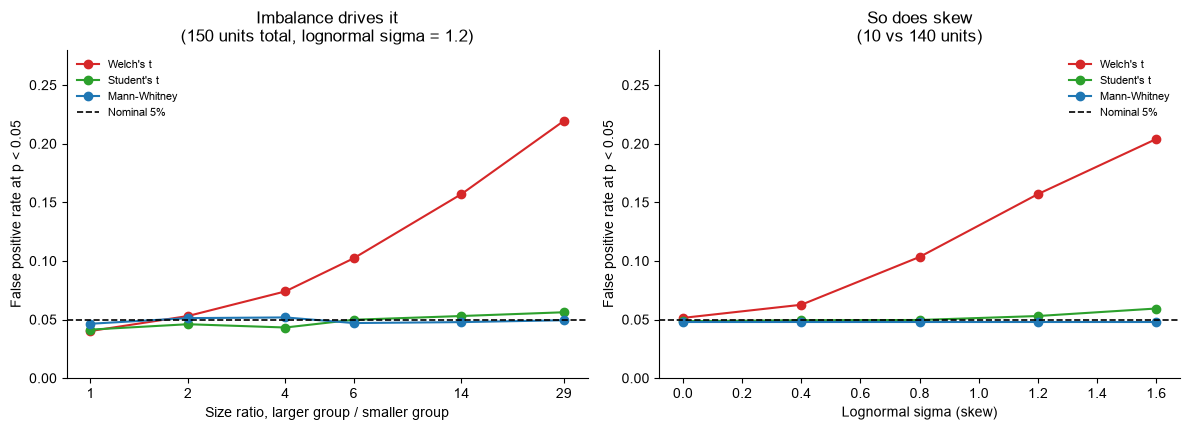

    n1 vs n2   ratio |   Welch  Student  MannWh
    75 vs 75     1.0 |   0.040    0.041   0.046
   50 vs 100     2.0 |   0.053    0.046   0.051
   30 vs 120     4.0 |   0.074    0.043   0.052
   20 vs 130     6.5 |   0.102    0.050   0.047
   10 vs 140    14.0 |   0.157    0.053   0.048
    5 vs 145    29.0 |   0.219    0.056   0.049

       sigma         |   Welch  Student  MannWh
      0.0001         |   0.051    0.049   0.048
      0.4000         |   0.063    0.049   0.048
      0.8000         |   0.103    0.050   0.048
      1.2000         |   0.157    0.053   0.048
      1.6000         |   0.204    0.059   0.048


In [6]:
def rates(n1, n2, sigma, nrep=5000, seed=0):
    rng = np.random.default_rng(seed)
    a = MED * np.exp(rng.normal(0, sigma, (nrep, n1)))
    b = MED * np.exp(rng.normal(0, sigma, (nrep, n2)))
    return (np.mean(stats.ttest_ind(a, b, axis=1, equal_var=False).pvalue < 0.05),
            np.mean(stats.ttest_ind(a, b, axis=1, equal_var=True).pvalue < 0.05),
            np.mean(stats.mannwhitneyu(a, b, axis=1,
                                       alternative='two-sided').pvalue < 0.05))

n1_grid = [75, 50, 30, 20, 10, 5]
sig_grid = [0.0001, 0.4, 0.8, 1.2, 1.6]
sw_n = np.array([rates(n1, 150 - n1, SIG) for n1 in n1_grid])
sw_s = np.array([rates(A.size, B.size, sg) for sg in sig_grid])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
ratio = [(150 - n1) / n1 for n1 in n1_grid]
for col, lab, c in ((0, "Welch's t", 'tab:red'), (1, "Student's t", 'tab:green'),
                    (2, 'Mann-Whitney', 'tab:blue')):
    axes[0].plot(ratio, sw_n[:, col], 'o-', ms=6, color=c, label=lab)
    axes[1].plot(sig_grid, sw_s[:, col], 'o-', ms=6, color=c, label=lab)
for ax, xl, ti in ((axes[0], 'Size ratio, larger group / smaller group',
                    'Imbalance drives it\n(150 units total, lognormal sigma = 1.2)'),
                   (axes[1], 'Lognormal sigma (skew)',
                    f'So does skew\n({A.size} vs {B.size} units)')):
    ax.axhline(0.05, color='k', ls='--', lw=1.2, label='Nominal 5%')
    ax.set_xlabel(xl); ax.set_ylabel('False positive rate at p < 0.05')
    ax.set_title(ti); ax.set_ylim(0, 0.28)
    ax.legend(frameon=False, fontsize=8)
axes[0].set_xscale('log'); axes[0].set_xticks(ratio)
axes[0].set_xticklabels([f'{r:.0f}' if r >= 1 else f'{r:.1f}' for r in ratio])
axes[0].minorticks_off()
plt.tight_layout(); plt.show()

print(f'{"n1 vs n2":>12s} {"ratio":>7s} | {"Welch":>7s} {"Student":>8s} {"MannWh":>7s}')
for n1, r in zip(n1_grid, sw_n):
    print(f'{f"{n1} vs {150-n1}":>12s} {(150-n1)/n1:7.1f} | '
          f'{r[0]:7.3f} {r[1]:8.3f} {r[2]:7.3f}')
print(f'\n{"sigma":>12s} {"":>7s} | {"Welch":>7s} {"Student":>8s} {"MannWh":>7s}')
for sg, r in zip(sig_grid, sw_s):
    print(f'{sg:12.4f} {"":>7s} | {r[0]:7.3f} {r[1]:8.3f} {r[2]:7.3f}')


## Evidence 5 — Positive control: the calibrated tests still have power

A test that never rejects is calibrated too, and useless. So check that the
recommended alternatives detect a real difference when there is one. Here region
A's rate distribution is genuinely scaled up by a factor, and we ask how often
each test notices.

The rank test and the log-scale t-test behave sensibly. Welch's does something
worse than merely losing power: over part of this range its rejection rate goes
*down* as the true effect grows, because a real increase in region A partly
cancels the downward bias that was generating its false positives. A test whose
rejection rate is non-monotonic in the truth is not measuring the truth.

Note also the honest limitation: with only 10 units in region A you need roughly
a threefold difference before any correctly-calibrated test is likely to find it.
That is a real constraint of the design, not a defect of the tests.


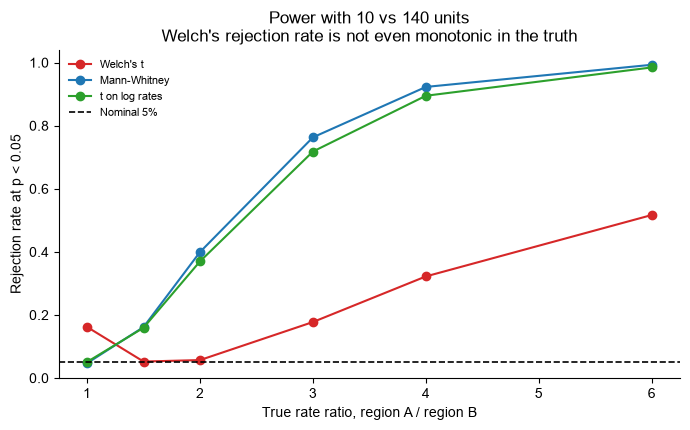

 true ratio |   Welch  MannWh   log t
        1.0 |   0.162   0.047   0.051
        1.5 |   0.052   0.162   0.159
        2.0 |   0.057   0.399   0.370
        3.0 |   0.178   0.763   0.718
        4.0 |   0.322   0.923   0.895
        6.0 |   0.517   0.993   0.985


In [7]:
def power(ratio, n1, n2, sigma=SIG, nrep=5000, seed=3):
    rng = np.random.default_rng(seed)
    a = MED * ratio * np.exp(rng.normal(0, sigma, (nrep, n1)))
    b = MED * np.exp(rng.normal(0, sigma, (nrep, n2)))
    return (np.mean(stats.ttest_ind(a, b, axis=1, equal_var=False).pvalue < 0.05),
            np.mean(stats.mannwhitneyu(a, b, axis=1,
                                       alternative='two-sided').pvalue < 0.05),
            np.mean(stats.ttest_ind(np.log(a), np.log(b), axis=1,
                                    equal_var=False).pvalue < 0.05))

ratios = np.array([1.0, 1.5, 2.0, 3.0, 4.0, 6.0])
pw = np.array([power(r, A.size, B.size) for r in ratios])

fig, ax = plt.subplots(figsize=(7.0, 4.4))
for col, lab, c in ((0, "Welch's t", 'tab:red'), (1, 'Mann-Whitney', 'tab:blue'),
                    (2, 't on log rates', 'tab:green')):
    ax.plot(ratios, pw[:, col], 'o-', ms=6, color=c, label=lab)
ax.axhline(0.05, color='k', ls='--', lw=1.2, label='Nominal 5%')
ax.set_xlabel('True rate ratio, region A / region B')
ax.set_ylabel('Rejection rate at p < 0.05')
ax.set_title(f'Power with {A.size} vs {B.size} units\n'
             "Welch's rejection rate is not even monotonic in the truth")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

print(f'{"true ratio":>11s} | {"Welch":>7s} {"MannWh":>7s} {"log t":>7s}')
for r, row in zip(ratios, pw):
    print(f'{r:11.1f} | {row[0]:7.3f} {row[1]:7.3f} {row[2]:7.3f}')


## Ground truth


In [8]:
gt = np.load('data/ground_truth.npz', allow_pickle=True)
tr = gt['true_rate']
print(f'true rates: median {np.median(tr):.2f}, '
      f'range {tr.min():.2f} to {tr.max():.1f} spikes/s')
print(f'true mean rate, region A units: {tr[region == 0].mean():.2f} spikes/s')
print(f'true mean rate, region B units: {tr[region == 1].mean():.2f} spikes/s')
print(f'  (both are estimates of the same population mean, '
      f'{float(gt["rate_median"])*np.exp(float(gt["rate_sigma"])**2/2):.2f})')
print()
print(str(gt['note']))


true rates: median 4.28, range 0.18 to 109.9 spikes/s
true mean rate, region A units: 5.11 spikes/s
true mean rate, region B units: 9.57 spikes/s
  (both are estimates of the same population mean, 8.22)

All 150 units' rates are drawn from ONE lognormal distribution (median 4 spikes/s, sigma 1.2). Region is assigned independently and has no effect on rate: the true A-vs-B difference is exactly zero. Welch's t-test is fooled because a sample of 10 from a heavy-tailed distribution usually misses the tail, which makes its mean AND its SD too small at once, and the test reads the small SD as precision.


## The lesson

- **The t-test's robustness to skew depends on balance.** With equal group sizes
  the skew in the two sample means largely cancels and the test is fine. With
  unequal sizes it does not cancel, and the smaller the small group, the worse it
  gets. Check the balance of your design before trusting a t-test on skewed data.

- **Welch's correction is the wrong default here.** Welch is the right advice for
  unequal *variances* under normality, but it buys that by trusting each group's
  own SD. When a small group's SD is unreliable, and for skewed data it is
  unreliable in a direction that is correlated with its mean, Welch converts the
  problem into false confidence. Student's pooled test was three times safer in
  this setting. Neither is the real fix.

- **What is the real fix.** A rank test (Mann-Whitney), a permutation test on the
  difference of means, or a t-test after a variance-stabilizing transform. For
  firing rates the log transform is the natural one, and not by coincidence: rates
  are lognormal, so the log scale is where the distribution is symmetric and where
  a difference of means is a ratio of rates, which is usually the biologically
  meaningful quantity anyway. Bootstrap confidence intervals on the difference of
  means also work.

- **Disagreement between the mean and the median is a warning.** Here the means
  differed by 47% in one direction and the medians by 14% in the other. That
  should stop the analysis, not appear as a footnote.

- **The central limit theorem is not a licence.** "n = 140, so the mean is
  normal" is not true for a distribution this skewed. Even at n = 140 the sample
  mean fell below the population mean 56% of the time and its SD was still
  strongly coupled to it.

- **This bias has a direction.** Unlike a shared-nuisance false positive, which
  flips sign at random, this one is systematic: the *small* group almost always
  looks quieter. Any literature comparing a rare, hard-to-sample population
  against an abundant one, with means and t-tests, will tend to report the rare
  population as less active. That is worth remembering when the small group is
  your interneuron subtype, your opto-tagged cells, or your thin nucleus.
